In [26]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from modules.benchmark import *
import plotly.express as px

In [27]:
avalon = load_cleaned()
avalon = drop_rheological(avalon)
avalon = add_avalon(avalon, columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(avalon)
X = drop_smiles(X)

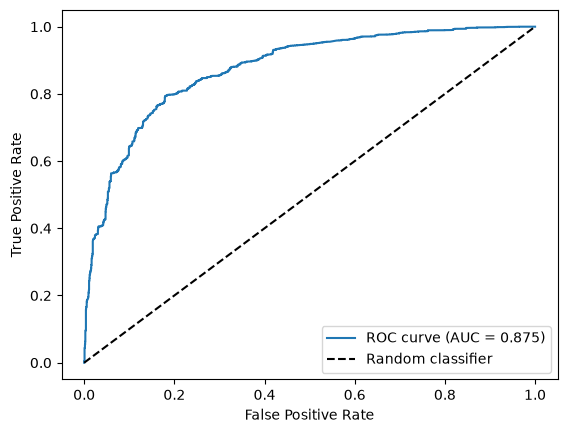

In [28]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [29]:
y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')

In [30]:
margin = np.abs(y_proba[:, 1] - y_proba[:, 0])

In [31]:
margin = pd.concat([avalon, pd.DataFrame(margin, columns=['margin'])], axis=1)

In [32]:
margin.head()

,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,smiles_additive1,...,additive2_avalon_247,additive2_avalon_248,additive2_avalon_249,additive2_avalon_250,additive2_avalon_251,additive2_avalon_252,additive2_avalon_253,additive2_avalon_254,additive2_avalon_255,margin
0,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.846621
1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.902996
2,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.980615
3,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.988035
4,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,[Cl-].[Na+],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.978442


In [33]:
fig = px.histogram(data_frame=margin, x="margin", title="Margin Distribution")
fig.update_traces(
    xbins=dict(
        start=0.0,
        end=1.0,
        size=0.05,
    )
)
fig.show()

In [34]:
filtered = margin[margin['margin'] < 0.05].sort_values(by='margin', ascending=True)
filtered[['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2', 'margin']]

,smiles_surfactant1,smiles_surfactant2,smiles_additive1,smiles_additive2,margin
5896,CCCCCCCCCCCC(=O)NC(CCC(=O)O)C(=O)[O-].OCC[NH+]...,CCCCCCCCCCCCCCCC[N+](C)(C)C.[Cl-],NaN,NaN,0.001487
2770,CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-],NaN,[Cl-].[K+],NaN,0.006266
6023,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],CCCCCCCCCCCCOC1COC2C(O)COC12,[Cl-].[Na+],NaN,0.006470
6019,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],CCCCCCCCCCCCOC1COC2C(O)COC12,[Cl-].[Na+],NaN,0.006470
6021,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],CCCCCCCCCCCCOC1COC2C(O)COC12,[Cl-].[Na+],NaN,0.006470
...,...,...,...,...,...
2040,CCCCCCCCCCCCOCCOCCOCCOS(=O)(=O)[O-].[Na+],CCCCCCCCCCCC(=O)N(C)CCO,NaN,NaN,0.049636
3072,CCCCCCCCCCCCOC1OC(CO)C(OC2OC(CO)C(O)C(O)C2O)C(...,NaN,NaN,NaN,0.049737
3073,CCCCCCCCCCCCOC1OC(CO)C(OC2OC(CO)C(O)C(O)C2O)C(...,NaN,NaN,NaN,0.049737
3222,CC(C)CCCC(C)C1CCC2C3CC=C4CC(OCCOCCOCCOCCOCCOCC...,CCCCCCCCCCCCOCCOCCOCCO,NC=O,NaN,0.049860


In [35]:
filtered['tuple'] = filtered.apply(lambda row: tuple([row['smiles_surfactant1'], row['smiles_surfactant2'], row['smiles_additive1'], row['smiles_additive1']]), axis=1)
filtered['tuple']

5896    (CCCCCCCCCCCC(=O)NC(CCC(=O)O)C(=O)[O-].OCC[NH+...
2770    (CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-...
6023    (CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na...
6019    (CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na...
6021    (CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na...
                              ...                        
2040    (CCCCCCCCCCCCOCCOCCOCCOS(=O)(=O)[O-].[Na+], CC...
3072    (CCCCCCCCCCCCOC1OC(CO)C(OC2OC(CO)C(O)C(O)C2O)C...
3073    (CCCCCCCCCCCCOC1OC(CO)C(OC2OC(CO)C(O)C(O)C2O)C...
3222    (CC(C)CCCC(C)C1CCC2C3CC=C4CC(OCCOCCOCCOCCOCCOC...
884     (CCCCCCCC/C=C\CCCCCCCC(=O)[O-].[Na+], nan, [Cl...
Name: tuple, Length: 74, dtype: object

In [36]:
filtered.groupby('tuple').size().reset_index(name="count").sort_values(by='count', ascending=False)

,tuple,count
6,(CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-...,14
25,"(CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+], nan, [Cl-]....",14
18,(CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na...,7
5,(CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-...,5
14,"(CCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-], nan, [Na+]...",4
20,"(CCCCCCCCCCCCOCCOCCOCCOS(=O)(=O)[O-].[Na+], CC...",3
15,"(CCCCCCCCCCCCCCCC[N+](C)(C)C.[Cl-], nan, O=C([...",2
10,(CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1...,2
8,(CCCCCCCCCCCC(=O)NC(CCC(=O)O)C(=O)[O-].OCC[NH+...,2
9,(CCCCCCCCCCCC(=O)NC(CCC(=O)O)C(=O)[O-].OCC[NH+...,2
